# LudoMax: Expectimax AI for Ludo under Dice Chance
**AL-2002 Artificial Intelligence Lab, Fall 2026**

Group: Saniya Asim (24K-3084), Aamna (24K-3001), Aisha Shaikh (24K-3026), BSE-5B

This notebook reproduces every number and chart in the project report. It uses our own Ludo engine
in `src/` (no external dataset). Games are simulated, and dice come from `random.Random(seed)`.

**Experiment design (as in the proposal):**
- 100 games per matchup, master seed 2002, game *i* uses seed `2002 + i`
- Seats are rotated every game, so each agent plays every colour equally often
- Win rate is reported with a 95% Wilson confidence interval
- Games that reach 2000 turns are counted as "timeout" (no winner)

Place this notebook in the project root (next to `src/` and `tests/`) and run all cells top to bottom (about 3 to 5 minutes). Results are saved to `outputs/results_full/` and `outputs/charts_full/`.

In [1]:
import os, sys, time, math, csv, subprocess
os.environ.setdefault('SDL_VIDEODRIVER', 'dummy'); os.environ.setdefault('SDL_AUDIODRIVER', 'dummy')
sys.path.insert(0, os.path.abspath('src'))

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

from board import COLORS
from game import Game
from agents import create_agent
from expectimax import ExpectimaxAgent

MASTER_SEED = 2002
N_GAMES = 100
MAX_TURNS = 2000
RES_DIR = 'outputs/results_full'; CH_DIR = 'outputs/charts_full'
os.makedirs(RES_DIR, exist_ok=True); os.makedirs(CH_DIR, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3})
AGENT_COLORS = {'Expectimax': '#1f77b4', 'Aggressive': '#d62728', 'Defensive': '#2ca02c', 'Random': '#7f7f7f'}
print('Setup OK')

Setup OK


## 1. Experiment helpers
`run_match(configs, n)` plays `n` games. `configs` is a list of 4 agent configurations. In game *i* the list
is rotated by `i % 4`, so every configuration sits in every colour equally often. Results are tracked per
configuration label, not per colour.

In [2]:
def wilson(k, n, z=1.96):
    if n == 0: return (0.0, 0.0)
    p = k / n
    d = 1 + z*z/n
    c = (p + z*z/(2*n)) / d
    h = z*math.sqrt(p*(1-p)/n + z*z/(4*n*n)) / d
    return (max(0.0, c-h), min(1.0, c+h))

def label(cfg):
    t = cfg['type'].capitalize()
    return f"{t}" if cfg['type'] != 'expectimax' else 'Expectimax'

def run_match(configs, n=N_GAMES, tag=''):
    # returns (per_game DataFrame, perf dict for expectimax agents)
    rows = []
    nodes = {}; decisions = {}; dtime = {}
    for i in range(n):
        seed = MASTER_SEED + i
        r = i % 4
        seat_cfg = [configs[(j + r) % 4] for j in range(4)]   # rotate seats
        agents = [create_agent(cfg['type'], COLORS[j], seed=seed*13 + j*31, depth=cfg.get('depth', 2))
                  for j, cfg in enumerate(seat_cfg)]
        g = Game(agents, seed=seed)
        winner_color = g.play_game(max_turns=MAX_TURNS)
        for j, cfg in enumerate(seat_cfg):
            col = COLORS[j]
            ag = agents[j]
            if isinstance(ag, ExpectimaxAgent):
                k = (cfg.get('label') or label(cfg))
                nodes[k] = nodes.get(k, 0) + ag.total_nodes
                decisions[k] = decisions.get(k, 0) + ag.total_decisions
                dtime[k] = dtime.get(k, 0.0) + ag.total_decision_time
            rows.append(dict(game=i, seed=seed, seat=col, agent=cfg.get('label') or label(cfg),
                             won=int(winner_color == col), timeout=int(winner_color is None),
                             captures_made=g.stats[col]['captures_made'],
                             captures_suffered=g.stats[col]['captures_suffered'],
                             pieces_home=g.state.pieces_finished(col),
                             game_turns=g.turn_count))
    perf = {k: dict(nodes=nodes[k], decisions=decisions[k], time=dtime[k]) for k in nodes}
    return pd.DataFrame(rows), perf

def summarize(df):
    out = []
    for a, d in df.groupby('agent', sort=False):
        n = len(d); k = int(d.won.sum()); lo, hi = wilson(k, n)
        out.append(dict(agent=a, games=n, wins=k, win_rate=k/n, ci_low=lo, ci_high=hi,
                        avg_captures_made=d.captures_made.mean(),
                        avg_captures_suffered=d.captures_suffered.mean(),
                        avg_pieces_home=d.pieces_home.mean(),
                        avg_game_turns=d.game_turns.mean(), timeouts=int(d.timeout.sum()/1)))
    return pd.DataFrame(out)

# quick smoke test
_df, _ = run_match([{'type':'expectimax','depth':2},{'type':'aggressive'},{'type':'defensive'},{'type':'random'}], n=4)
print(summarize(_df).round(3))

        agent  games  wins  win_rate  ci_low  ci_high  avg_captures_made  \
0  Expectimax      4     3      0.75   0.301    0.954               5.50   
1  Aggressive      4     0      0.00   0.000    0.490               6.50   
2   Defensive      4     1      0.25   0.046    0.699               2.00   
3      Random      4     0      0.00   0.000    0.490               3.75   

   avg_captures_suffered  avg_pieces_home  avg_game_turns  timeouts  
0                   3.25             3.75           423.0         0  
1                   4.50             2.25           423.0         0  
2                   3.50             2.75           423.0         0  
3                   6.50             1.75           423.0         0  


## 2. Experiment A: 4-player free-for-all
Expectimax (depth 2), Aggressive, Defensive and Random play together. A fair win rate is 25%.

In [3]:
cfg4 = [{'type':'expectimax','depth':2}, {'type':'aggressive'}, {'type':'defensive'}, {'type':'random'}]
t0 = time.time()
dfA, perfA = run_match(cfg4)
sumA = summarize(dfA)
sumA.to_csv(f'{RES_DIR}/A_four_way_summary.csv', index=False)
dfA.to_csv(f'{RES_DIR}/A_four_way_games.csv', index=False)
print(f'{time.time()-t0:.1f}s')
sumA.round(3)

3.2s


,agent,games,wins,win_rate,ci_low,ci_high,avg_captures_made,avg_captures_suffered,avg_pieces_home,avg_game_turns,timeouts
0,Expectimax,100,48,0.48,0.385,0.577,6.34,3.08,3.06,371.43,0
1,Aggressive,100,32,0.32,0.237,0.417,5.01,3.77,2.75,371.43,0
2,Defensive,100,18,0.18,0.117,0.267,3.65,3.52,2.14,371.43,0
3,Random,100,2,0.02,0.006,0.070,2.03,6.66,0.93,371.43,0


## 3. Experiment B: head-to-head matrix (1 agent vs 3 copies of another)
Row agent plays against three copies of the column agent. The fair win rate is 25% (one seat of four).
Expectimax uses depth 2 here.

In [4]:
types = ['expectimax', 'aggressive', 'defensive', 'random']
names = ['Expectimax', 'Aggressive', 'Defensive', 'Random']
mat = pd.DataFrame(np.nan, index=names, columns=names)
mat_lo = mat.copy(); mat_hi = mat.copy()
rows = []
t0 = time.time()
for a, an in zip(types, names):
    for b, bn in zip(types, names):
        if a == b: continue
        ca = {'type': a, 'depth': 2, 'label': 'A'}
        cb = {'type': b, 'depth': 2, 'label': 'B'}
        df, _ = run_match([ca, cb, cb, cb])
        d = df[df.agent == 'A']
        k = int(d.won.sum()); lo, hi = wilson(k, len(d))
        mat.loc[an, bn] = k/len(d); mat_lo.loc[an, bn] = lo; mat_hi.loc[an, bn] = hi
        rows.append(dict(agent=an, vs_3x=bn, games=len(d), wins=k, win_rate=k/len(d), ci_low=lo, ci_high=hi,
                         avg_captures_made=d.captures_made.mean(), avg_captures_suffered=d.captures_suffered.mean()))
pd.DataFrame(rows).to_csv(f'{RES_DIR}/B_head_to_head.csv', index=False)
print(f'{time.time()-t0:.1f}s')
(mat*100).round(1)

39.1s


,Expectimax,Aggressive,Defensive,Random
Expectimax,NaN,26.0,45.0,77.0
Aggressive,33.0,NaN,44.0,68.0
Defensive,11.0,19.0,NaN,62.0
Random,1.0,3.0,5.0,NaN


## 4. Experiment C: effect of search depth
Expectimax at depth 1, 2, 3, each tested (a) against 3 Random players and (b) in the mixed 4-player game
(vs Aggressive, Defensive, Random). We also record nodes expanded and time per decision.

In [5]:
depth_rows = []; perf_rows = []
t0 = time.time()
for d in (1, 2, 3):
    for setting, others in [('vs 3 Random', [{'type':'random'}]*3),
                            ('4-way mixed', [{'type':'aggressive'}, {'type':'defensive'}, {'type':'random'}])]:
        cfgs = [{'type':'expectimax', 'depth': d, 'label': 'E'}] + others
        df, perf = run_match(cfgs)
        e = df[df.agent == 'E']
        k = int(e.won.sum()); lo, hi = wilson(k, len(e))
        depth_rows.append(dict(depth=d, setting=setting, games=len(e), wins=k, win_rate=k/len(e),
                               ci_low=lo, ci_high=hi, avg_captures_made=e.captures_made.mean(),
                               avg_captures_suffered=e.captures_suffered.mean(), avg_game_turns=e.game_turns.mean()))
        p = perf['E']
        perf_rows.append(dict(depth=d, setting=setting, decisions=p['decisions'],
                              avg_nodes=p['nodes']/p['decisions'], avg_time_ms=1000*p['time']/p['decisions']))
depthDF = pd.DataFrame(depth_rows); perfDF = pd.DataFrame(perf_rows)
depthDF.to_csv(f'{RES_DIR}/C_depth_comparison.csv', index=False)
perfDF.to_csv(f'{RES_DIR}/C_performance.csv', index=False)
print(f'{time.time()-t0:.1f}s')
display(depthDF.round(3)); display(perfDF.round(3))

65.2s


,depth,setting,games,wins,win_rate,ci_low,ci_high,avg_captures_made,avg_captures_suffered,avg_game_turns
0,1,vs 3 Random,100,71,0.71,0.615,0.790,7.49,1.72,362.86
1,1,4-way mixed,100,53,0.53,0.433,0.625,5.13,2.71,371.25
2,2,vs 3 Random,100,77,0.77,0.678,0.842,8.48,1.92,373.88
3,2,4-way mixed,100,48,0.48,0.385,0.577,6.34,3.08,371.43
4,3,vs 3 Random,100,69,0.69,0.594,0.772,8.40,1.89,368.18
5,3,4-way mixed,100,43,0.43,0.337,0.528,6.13,3.14,373.98


,depth,setting,decisions,avg_nodes,avg_time_ms
0,1,vs 3 Random,6255,2.410,0.030
1,1,4-way mixed,6143,2.367,0.031
2,2,vs 3 Random,6410,44.876,0.349
3,2,4-way mixed,6279,44.664,0.398
4,3,vs 3 Random,6321,535.272,4.264
5,3,4-way mixed,6200,549.275,5.019


## 5. Charts
Five charts, as planned in the proposal.

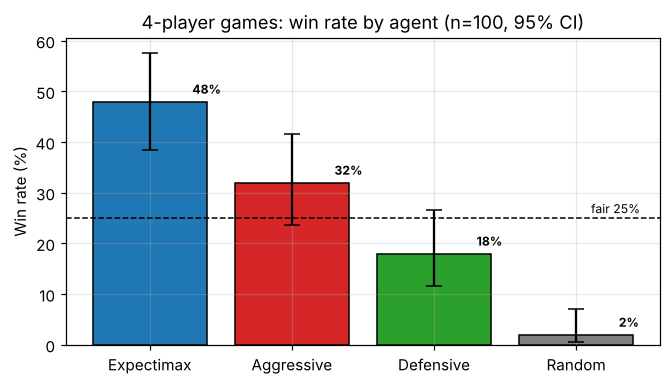

In [6]:
# Chart 1: 4-way win rate with 95% CI
fig, ax = plt.subplots(figsize=(6.2, 3.6))
s = sumA.set_index('agent').loc[names]
err = [ (s.win_rate - s.ci_low)*100, (s.ci_high - s.win_rate)*100 ]
ax.bar(names, s.win_rate*100, yerr=err, capsize=5, color=[AGENT_COLORS[n] for n in names], edgecolor='black')
ax.axhline(25, color='k', ls='--', lw=1); ax.text(3.45, 26, 'fair 25%', ha='right', fontsize=8)
ax.set_ylabel('Win rate (%)'); ax.set_title('4-player games: win rate by agent (n=100, 95% CI)')
for i, n in enumerate(names):
    ax.text(i + 0.3, s.win_rate[n]*100 + 1, f"{s.win_rate[n]*100:.0f}%", ha='left', va='bottom', fontsize=8, fontweight='bold')
plt.tight_layout(); plt.savefig(f'{CH_DIR}/chart1_four_way_win_rate.png', dpi=200); plt.show()

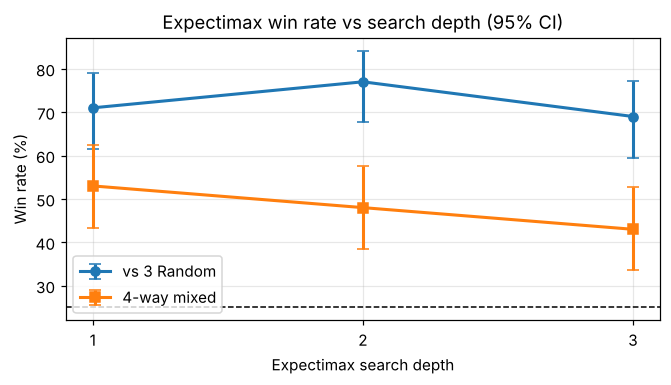

In [7]:
# Chart 2: win rate vs depth
fig, ax = plt.subplots(figsize=(6.2, 3.6))
for setting, mk in [('vs 3 Random', 'o'), ('4-way mixed', 's')]:
    d = depthDF[depthDF.setting == setting]
    ax.errorbar(d.depth, d.win_rate*100, yerr=[(d.win_rate-d.ci_low)*100, (d.ci_high-d.win_rate)*100],
                marker=mk, capsize=4, label=setting, lw=2)
ax.axhline(25, color='k', ls='--', lw=1)
ax.set_xticks([1, 2, 3]); ax.set_xlabel('Expectimax search depth'); ax.set_ylabel('Win rate (%)')
ax.set_title('Expectimax win rate vs search depth (95% CI)'); ax.legend()
plt.tight_layout(); plt.savefig(f'{CH_DIR}/chart2_depth_vs_win_rate.png', dpi=200); plt.show()

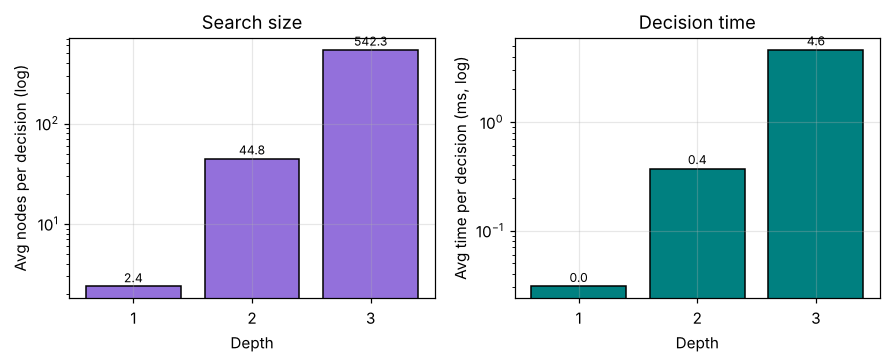

In [8]:
# Chart 3: nodes and time per decision vs depth
p = perfDF.groupby('depth')[['avg_nodes', 'avg_time_ms']].mean()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(8.2, 3.4))
a1.bar(p.index.astype(str), p.avg_nodes, color='mediumpurple', edgecolor='black'); a1.set_yscale('log')
a1.set_xlabel('Depth'); a1.set_ylabel('Avg nodes per decision (log)'); a1.set_title('Search size')
a2.bar(p.index.astype(str), p.avg_time_ms, color='teal', edgecolor='black'); a2.set_yscale('log')
a2.set_xlabel('Depth'); a2.set_ylabel('Avg time per decision (ms, log)'); a2.set_title('Decision time')
for ax_, col in ((a1, 'avg_nodes'), (a2, 'avg_time_ms')):
    for i, v in enumerate(p[col]): ax_.text(i, v*1.1, f'{v:,.1f}', ha='center', fontsize=8)
plt.tight_layout(); plt.savefig(f'{CH_DIR}/chart3_nodes_time_vs_depth.png', dpi=200); plt.show()

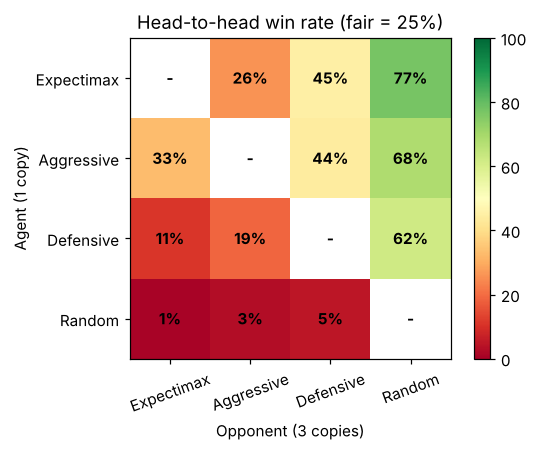

In [9]:
# Chart 4: head-to-head matrix (row agent vs 3x column agent)
fig, ax = plt.subplots(figsize=(5.4, 4.2))
M = (mat*100).values
im = ax.imshow(M, cmap='RdYlGn', vmin=0, vmax=100)
ax.set_xticks(range(4)); ax.set_xticklabels(names, rotation=20); ax.set_yticks(range(4)); ax.set_yticklabels(names)
ax.set_xlabel('Opponent (3 copies)'); ax.set_ylabel('Agent (1 copy)'); ax.grid(False)
for i in range(4):
    for j in range(4):
        ax.text(j, i, '-' if i == j else f'{M[i,j]:.0f}%', ha='center', va='center', fontweight='bold')
ax.set_title('Head-to-head win rate (fair = 25%)'); plt.colorbar(im, fraction=.046)
plt.tight_layout(); plt.savefig(f'{CH_DIR}/chart4_head_to_head_matrix.png', dpi=200); plt.show()

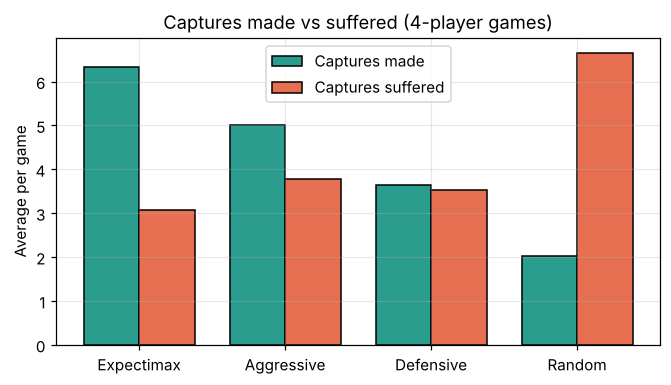

In [10]:
# Chart 5: captures made vs suffered (4-way)
fig, ax = plt.subplots(figsize=(6.2, 3.6))
x = np.arange(4); w = .38
ax.bar(x - w/2, s.avg_captures_made, w, label='Captures made', color='#2a9d8f', edgecolor='black')
ax.bar(x + w/2, s.avg_captures_suffered, w, label='Captures suffered', color='#e76f51', edgecolor='black')
ax.set_xticks(x); ax.set_xticklabels(names); ax.set_ylabel('Average per game')
ax.set_title('Captures made vs suffered (4-player games)'); ax.legend()
plt.tight_layout(); plt.savefig(f'{CH_DIR}/chart5_captures.png', dpi=200); plt.show()

## 6. Worked example: what Expectimax sees at one decision
We play a seeded game and stop at the first decision where Expectimax (depth 2) has at least 3 different legal moves.
For each candidate move we print the expected value from the search, then the move the agent chooses.

In [11]:
def find_decision(seed=2002, depth=2):
    agents = [create_agent('expectimax', 'yellow', depth=depth)] + [create_agent('random', c, seed=seed+i) for i, c in enumerate(COLORS[1:])]
    g = Game(agents, seed=seed)
    ex = agents[0]
    for _ in range(600):
        player = g.state.current_player
        dice = g.roll_dice()
        legal = g.state.get_legal_moves(dice)
        if player == 'yellow' and len(ex._deduplicate_moves(legal)) >= 3 and g.state.consecutive_sixes == 0:
            return g, ex, dice, legal
        g.play_turn(dice=dice)
    return None

g, ex, dice, legal = find_decision()
print('Current state:'); print(g.state); print('Dice rolled:', dice)
print()
for m in ex._deduplicate_moves(legal):
    ns = g.state.apply_move(m, dice)
    val = ex._chance_node(ns, ex.depth - 1, ns.current_player == 'yellow')
    print(f'piece {m.piece_index}: {m.from_progress:>2} -> {m.to_progress:>2}  captures={m.captures}  expected value = {val:8.1f}')
best = ex.choose_move(g.state, legal, dice)
print('\nExpectimax chooses piece', best.piece_index, f'({best.from_progress} -> {best.to_progress})')

Current state:
GameState(current=yellow, consec6=0)
  yellow: [41, 1, -1, -1]
  blue: [0, -1, 0, -1]
  red: [-1, -1, 22, -1]
  green: [56, -1, -1, 8]
Dice rolled: 6

piece 0: 41 -> 47  captures=[]  expected value =    444.1
piece 1:  1 ->  7  captures=[]  expected value =    423.0
piece 2: -1 ->  0  captures=[]  expected value =    487.0

Expectimax chooses piece 2 (-1 -> 0)


## 7. Unit tests
The test suite checks the rules (captures, safe squares, exact finish, three sixes), the agents, Expectimax, the
tournament runner and the headless GUI.

In [12]:
r = subprocess.run([sys.executable, '-m', 'pytest', 'tests', '-q', '-p', 'no:cacheprovider'],
                   capture_output=True, text=True, env={**os.environ, 'SDL_VIDEODRIVER': 'dummy', 'SDL_AUDIODRIVER': 'dummy'})
print(r.stdout[-400:] or r.stderr[-400:])

................................             [100%]
204 passed in 1.61s



## 8. Summary table (used in the report)

In [13]:
print('Experiment A: 4-player free-for-all'); display(sumA.round(3))
print('Timeouts in all games:', int(dfA.timeout.sum()/4))
print('\nExperiment B: head-to-head (win %, row vs 3x column)'); display((mat*100).round(1))
print('\nExperiment C: depth comparison'); display(depthDF.round(3)); display(perfDF.round(3))

Experiment A: 4-player free-for-all


,agent,games,wins,win_rate,ci_low,ci_high,avg_captures_made,avg_captures_suffered,avg_pieces_home,avg_game_turns,timeouts
0,Expectimax,100,48,0.48,0.385,0.577,6.34,3.08,3.06,371.43,0
1,Aggressive,100,32,0.32,0.237,0.417,5.01,3.77,2.75,371.43,0
2,Defensive,100,18,0.18,0.117,0.267,3.65,3.52,2.14,371.43,0
3,Random,100,2,0.02,0.006,0.070,2.03,6.66,0.93,371.43,0


Timeouts in all games: 0

Experiment B: head-to-head (win %, row vs 3x column)


,Expectimax,Aggressive,Defensive,Random
Expectimax,NaN,26.0,45.0,77.0
Aggressive,33.0,NaN,44.0,68.0
Defensive,11.0,19.0,NaN,62.0
Random,1.0,3.0,5.0,NaN



Experiment C: depth comparison


,depth,setting,games,wins,win_rate,ci_low,ci_high,avg_captures_made,avg_captures_suffered,avg_game_turns
0,1,vs 3 Random,100,71,0.71,0.615,0.790,7.49,1.72,362.86
1,1,4-way mixed,100,53,0.53,0.433,0.625,5.13,2.71,371.25
2,2,vs 3 Random,100,77,0.77,0.678,0.842,8.48,1.92,373.88
3,2,4-way mixed,100,48,0.48,0.385,0.577,6.34,3.08,371.43
4,3,vs 3 Random,100,69,0.69,0.594,0.772,8.40,1.89,368.18
5,3,4-way mixed,100,43,0.43,0.337,0.528,6.13,3.14,373.98


,depth,setting,decisions,avg_nodes,avg_time_ms
0,1,vs 3 Random,6255,2.410,0.030
1,1,4-way mixed,6143,2.367,0.031
2,2,vs 3 Random,6410,44.876,0.349
3,2,4-way mixed,6279,44.664,0.398
4,3,vs 3 Random,6321,535.272,4.264
5,3,4-way mixed,6200,549.275,5.019
